# Student Depression Classification

## Decision Tree Classifier

### 1. Introduction

This notebook focuses on building, training, and evaluating a **Decision Tree Classifier** to predict student depression based on demographic, academic, social, economic, and health-related features.

A Decision Tree is a supervised machine learning algorithm that makes predictions by learning a sequence of decision rules from the training data.

It recursively splits the dataset into smaller subsets based on feature values until it reaches a prediction decision.

### 2. Objectives

The main objectives of this notebook are:

- Understand how Decision Tree classification works.
- Prepare the dataset for model training.
- Build and evaluate an initial Decision Tree model.
- Optimize model performance using hyperparameter tuning.
- Evaluate the model using appropriate classification metrics.
- Visualize the decision tree and interpret its decision rules.
- Analyze feature importance.
- Investigate the impact of individual features on model performance.
- Examine potential overfitting and data-related limitations.

### 3. Dataset Overview

The dataset contains **4,464 observations and 13 columns**, including:

- Demographic information.
- Academic characteristics.
- Social and family background.
- Economic information.
- Health-related information.

The target variable is:

- `Depression`: Indicates whether a student belongs to the positive or negative depression class.

### 4. Methodology

The notebook follows these main steps:

1. Import the required libraries and load the dataset.
2. Perform data preparation and preprocessing.
3. Separate input features and target variable.
4. Split the data into training and testing sets using stratified sampling.
5. Build an initial Decision Tree Classifier.
6. Evaluate the initial model.
7. Optimize hyperparameters using GridSearchCV.
8. Evaluate the tuned model.
9. Compare the model against a Dummy Classifier baseline.
10. Analyze feature importance and visualize the decision tree.
11. Investigate the influence of the `Health_condition` feature.
12. Evaluate model stability using cross-validation.

### 5. Evaluation Metrics

The model will be evaluated using:

- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Proportion of correctly predicted positive cases.
- **Recall:** Proportion of actual positive cases correctly identified.
- **F1-score:** Harmonic mean of Precision and Recall.
- **Confusion Matrix:** Provides a detailed view of correct and incorrect predictions.

Cross-validation will also be used to assess the consistency of model performance.

### 6. Important Considerations

The dataset contains a strong association between `Health_condition` and the target variable `Depression`.

This relationship requires further investigation to determine whether the feature contains information that may have been used during target-label creation.

High model performance alone does not prove target leakage, causation, or clinical validity.

This project is intended for educational and machine learning practice purposes only. The model is not designed for clinical diagnosis.

In [41]:
# Import Libraries & Load Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    make_scorer
)

In [3]:
df = pd.read_csv("../data/raw/Student_Depression_Dataset.csv")

In [4]:
df.shape

(4464, 13)

In [5]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 722.9 KB


In [7]:
# Data Preparation
X = df.drop(columns=["Depression"])
y = df["Depression"].map({"No": 0,"Yes": 1})

In [8]:
print("\nTarget distribution:")
print(df["Depression"].value_counts())
print("\nTarget proportions:")
print(df["Depression"].value_counts(normalize=True).round(3))


Target distribution:
Depression
No     3263
Yes    1201
Name: count, dtype: int64

Target proportions:
Depression
No     0.731
Yes    0.269
Name: proportion, dtype: float64


In [9]:
# Feature Identification
num_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

cat_cols = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

In [10]:
print("\nNumerical features:", num_cols)
print("Categorical features:", cat_cols)


Numerical features: ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Categorical features: ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division']


In [11]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])



Training samples: 3571
Testing samples: 893


In [12]:
# Pass numerical features through without transformation
preprocessor = ColumnTransformer(
    transformers=[
        ("encoder", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ],
    remainder="passthrough"
)

In [13]:
# Build a pipeline combining preprocessing and Decision Tree classification
tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

In [14]:
# Train the initial Decision Tree model
tree_pipeline.fit(X_train, y_train)
# Generate predictions on the training and testing sets
train_predictions = tree_pipeline.predict(X_train)
test_predictions = tree_pipeline.predict(X_test)

In [15]:
# Compare training and testing accuracy
print("\nINITIAL MODEL")
print("Train Accuracy:", accuracy_score(y_train, train_predictions))
print("Test Accuracy:", accuracy_score(y_test, test_predictions))

# Evaluate the classification performance on the test set
print("\nInitial classification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No", "Yes"],
    zero_division=0
))



INITIAL MODEL
Train Accuracy: 1.0
Test Accuracy: 0.9966405375139977

Initial classification report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00       653
         Yes       1.00      0.99      0.99       240

    accuracy                           1.00       893
   macro avg       1.00      0.99      1.00       893
weighted avg       1.00      1.00      1.00       893



In [16]:
# Define the hyperparameter combinations to evaluate
param_grid = {
    "classifier__max_depth": [3, 5, 8, 12, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10]
}
# Configure GridSearchCV to find the best hyperparameter combination
# F1-score is used to evaluate positive-class performance
grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True
)

In [17]:
# Perform hyperparameter tuning using the training data
grid_search.fit(X_train, y_train)

# Retrieve the best-performing pipeline
best_model = grid_search.best_estimator_

In [18]:
# Display the optimal hyperparameters and cross-validation score
print("\nBEST PARAMETERS:")
print(grid_search.best_params_)
print("\nBest mean cross-validation F1:", grid_search.best_score_)


BEST PARAMETERS:
{'classifier__max_depth': 12, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 20}

Best mean cross-validation F1: 0.9790101965357445


In [19]:
# Generate predictions using the tuned model
train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

In [20]:
# Evaluate training and testing accuracy
print("\nTUNED MODEL")
print("Train Accuracy:", accuracy_score(y_train, train_predictions))
print("Test Accuracy:", accuracy_score(y_test, test_predictions))

# Calculate precision, recall, and F1-score for the positive class
print("\nTest Precision:", precision_score(
    y_test, test_predictions, zero_division=0
))
print("Test Recall:", recall_score(
    y_test, test_predictions, zero_division=0
))
print("Test F1-score:", f1_score(
    y_test, test_predictions, zero_division=0
))

# Display the complete classification report
print("\nFinal classification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No", "Yes"],
    zero_division=0
))



TUNED MODEL
Train Accuracy: 0.9955194623354803
Test Accuracy: 0.9910414333706606

Test Precision: 0.9833333333333333
Test Recall: 0.9833333333333333
Test F1-score: 0.9833333333333333

Final classification report:
              precision    recall  f1-score   support

          No       0.99      0.99      0.99       653
         Yes       0.98      0.98      0.98       240

    accuracy                           0.99       893
   macro avg       0.99      0.99      0.99       893
weighted avg       0.99      0.99      0.99       893



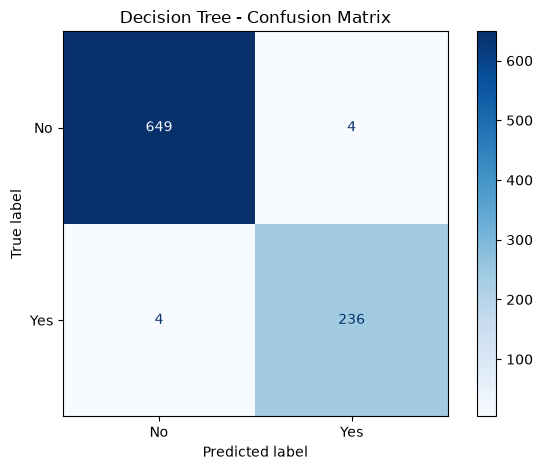

In [21]:
# Visualize the confusion matrix of the tuned Decision Tree model
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

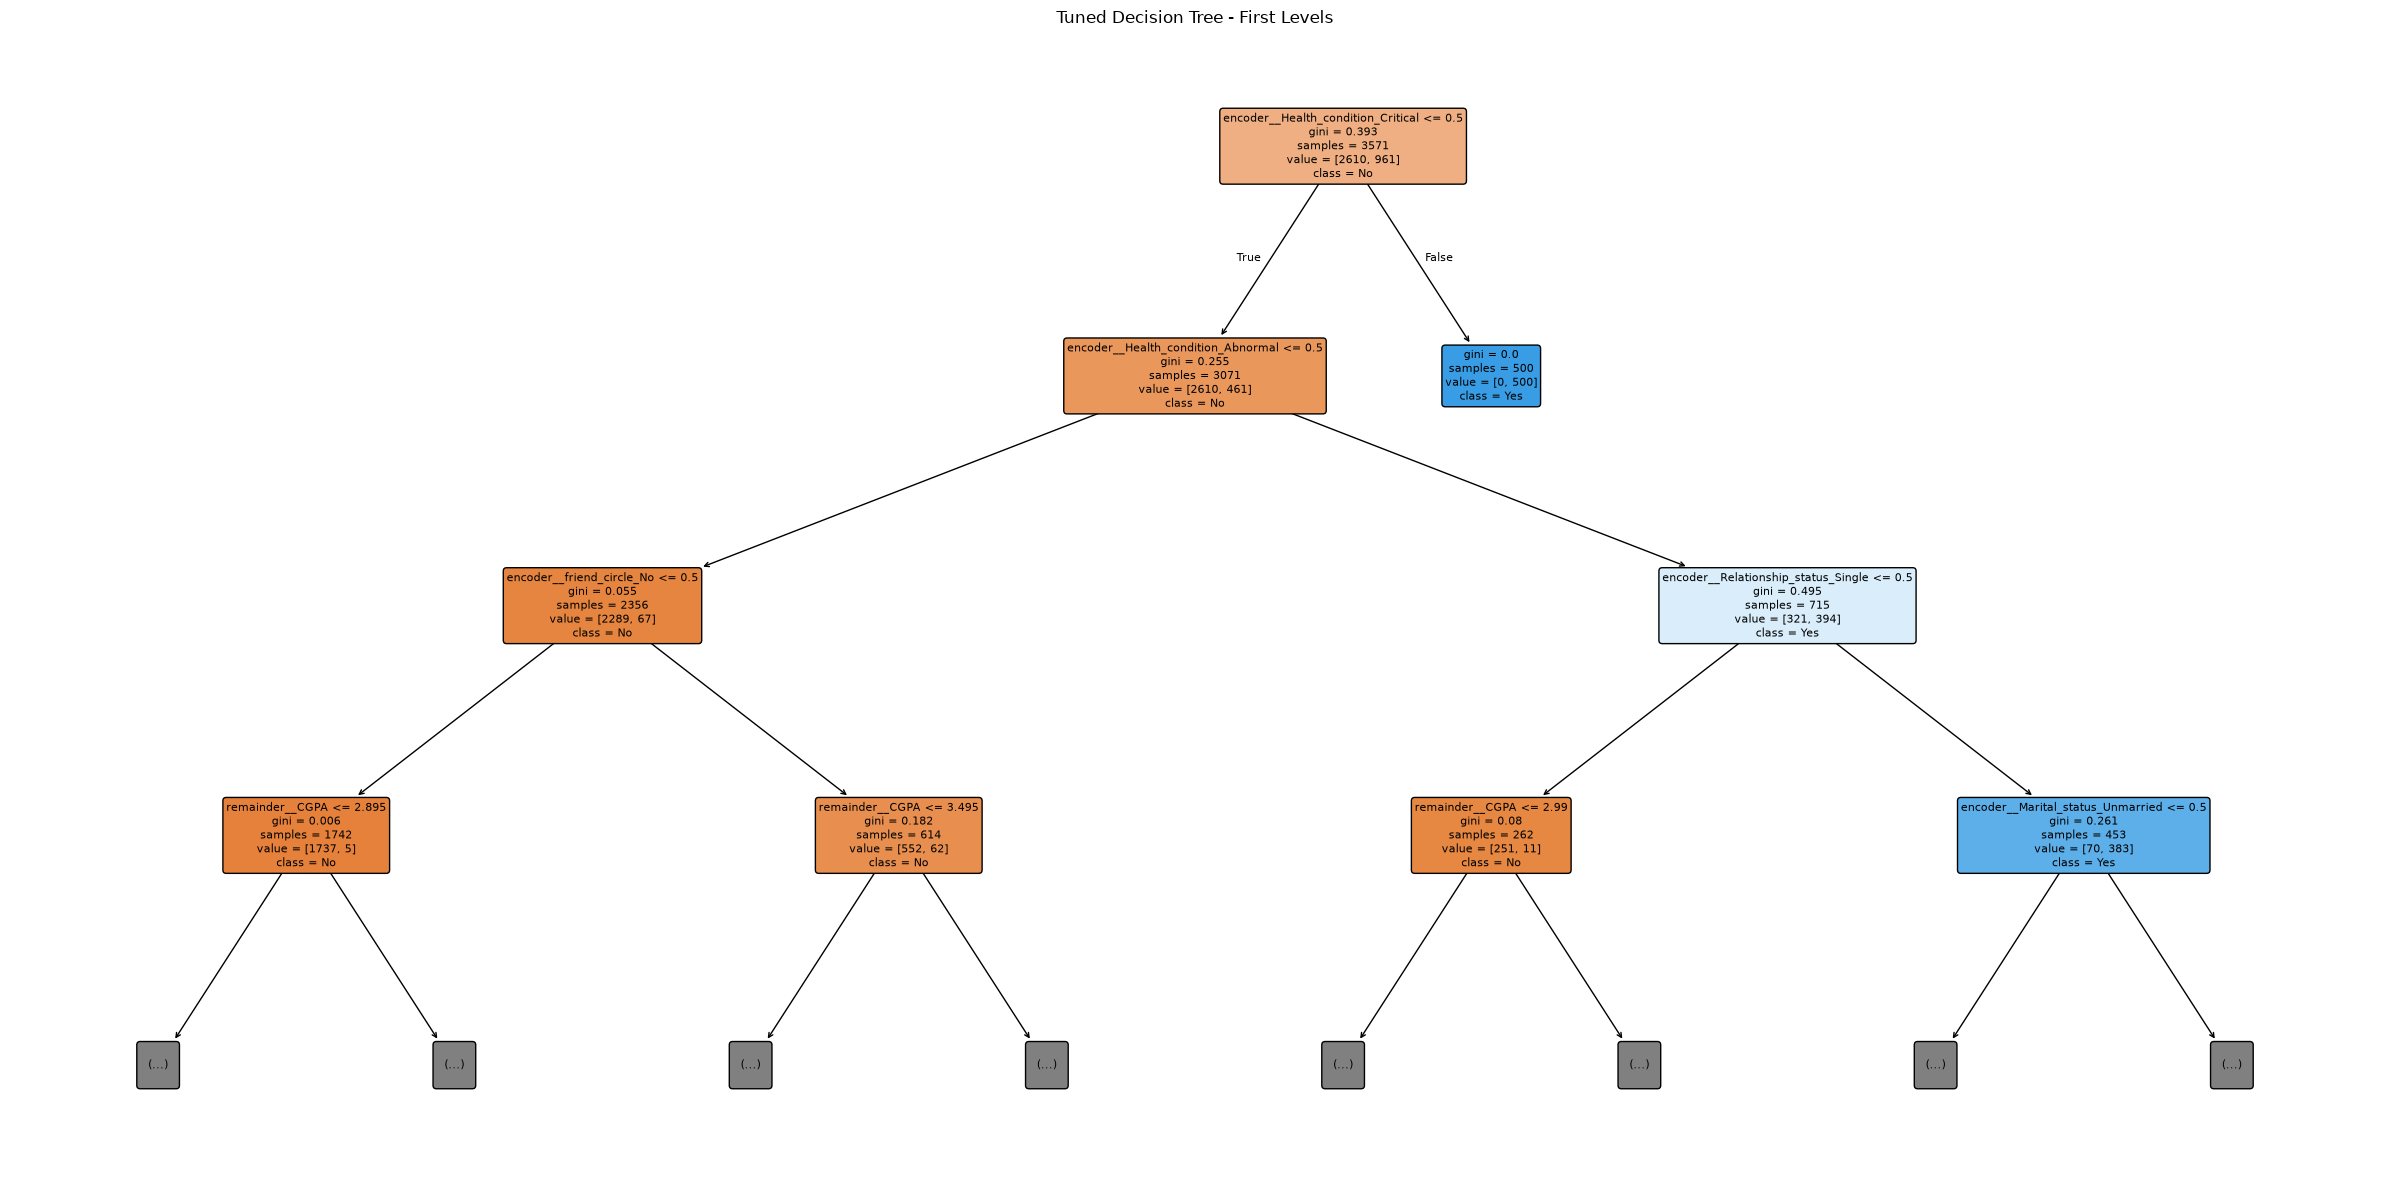

In [22]:
# Extract the fitted preprocessing and Decision Tree components
fitted_preprocessor = best_model.named_steps["preprocessor"]
best_tree = best_model.named_steps["classifier"]

# Retrieve feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Visualize the first levels of the trained Decision Tree
plt.figure(figsize=(24, 12))

plot_tree(
    best_tree,
    feature_names=feature_names,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Tuned Decision Tree - First Levels")
plt.tight_layout()
plt.show()

In [23]:
# Dummy Classifier Baseline
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline F1:",
      f1_score(y_test, baseline_predictions, zero_division=0))

Baseline Accuracy: 0.7312430011198209
Baseline F1: 0.0


In [24]:
# Decision Tree Without Health Condition
X_without_health = X.drop(columns=["Health_condition"])
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_without_health,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
num_cols_new = X_train_new.select_dtypes(include="number").columns
cat_cols_new = X_train_new.select_dtypes(include="str").columns
preprocessor_new = ColumnTransformer(
    transformers=[
        ("encoder", OneHotEncoder(handle_unknown="ignore"), cat_cols_new)
    ],
    remainder="passthrough"
)
tree_pipeline_new = Pipeline([
    ("preprocessor_new", preprocessor_new),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])
tree_pipeline_new.fit(X_train_new, y_train_new)

train_predictions_new = tree_pipeline_new.predict(X_train_new)
test_predictions_new = tree_pipeline_new.predict(X_test_new)

print("\nINITIAL MODEL")
print("Train Accuracy:", accuracy_score(y_train_new, train_predictions_new))
print("Test Accuracy:", accuracy_score(y_test_new, test_predictions_new))

print("\nInitial classification report:")
print(classification_report(
    y_test_new,
    test_predictions_new,
    target_names=["No", "Yes"],
    zero_division=0
))



INITIAL MODEL
Train Accuracy: 0.9997199663959675
Test Accuracy: 0.6685330347144457

Initial classification report:
              precision    recall  f1-score   support

          No       0.78      0.75      0.77       653
         Yes       0.39      0.43      0.41       240

    accuracy                           0.67       893
   macro avg       0.59      0.59      0.59       893
weighted avg       0.68      0.67      0.67       893



In [25]:
# Hyperparameter Tuning Without Health Condition
param_grid = {
    "classifier__max_depth": [3, 5, 8, 12, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10]
}

grid_search_new = GridSearchCV(
    estimator=tree_pipeline_new,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True
)
grid_search_new.fit(X_train_new, y_train_new)

best_model_new = grid_search_new.best_estimator_
print("\nBEST PARAMETERS:")
print(grid_search_new.best_params_)
print("\nBest mean cross-validation F1:", grid_search_new.best_score_)


BEST PARAMETERS:
{'classifier__max_depth': 12, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best mean cross-validation F1: 0.4179281578469077


In [26]:
# Tuned Model Without Health Condition
train_predictions_new = best_model_new.predict(X_train_new)
test_predictions_new = best_model_new.predict(X_test_new)

In [27]:
print("\nTUNED MODEL")
print("Train Accuracy:", accuracy_score(y_train_new, train_predictions_new))
print("Test Accuracy:", accuracy_score(y_test_new, test_predictions_new))

print("\nTest Precision:", precision_score(
    y_test_new, test_predictions_new, zero_division=0
))
print("Test Recall:", recall_score(
    y_test_new, test_predictions_new, zero_division=0
))
print("Test F1-score:", f1_score(
    y_test_new, test_predictions_new, zero_division=0
))

print("\nFinal classification report:")
print(classification_report(
    y_test_new,
    test_predictions_new,
    target_names=["No", "Yes"],
    zero_division=0
))



TUNED MODEL
Train Accuracy: 0.9047885746289555
Test Accuracy: 0.6819708846584547

Test Precision: 0.4017857142857143
Test Recall: 0.375
Test F1-score: 0.3879310344827586

Final classification report:
              precision    recall  f1-score   support

          No       0.78      0.79      0.79       653
         Yes       0.40      0.38      0.39       240

    accuracy                           0.68       893
   macro avg       0.59      0.58      0.59       893
weighted avg       0.68      0.68      0.68       893



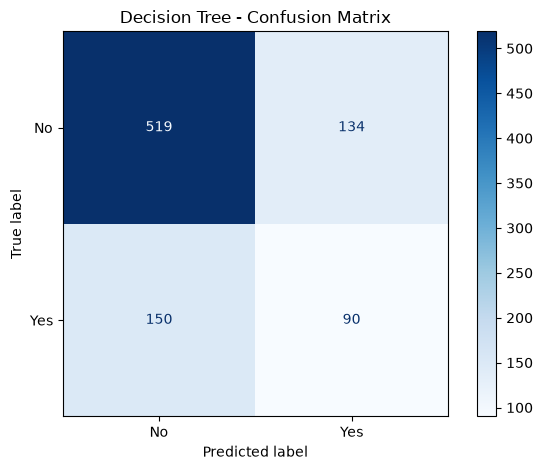

In [28]:
# Confusion Matrix Without Health Condition
ConfusionMatrixDisplay.from_predictions(
    y_test_new,
    test_predictions_new,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

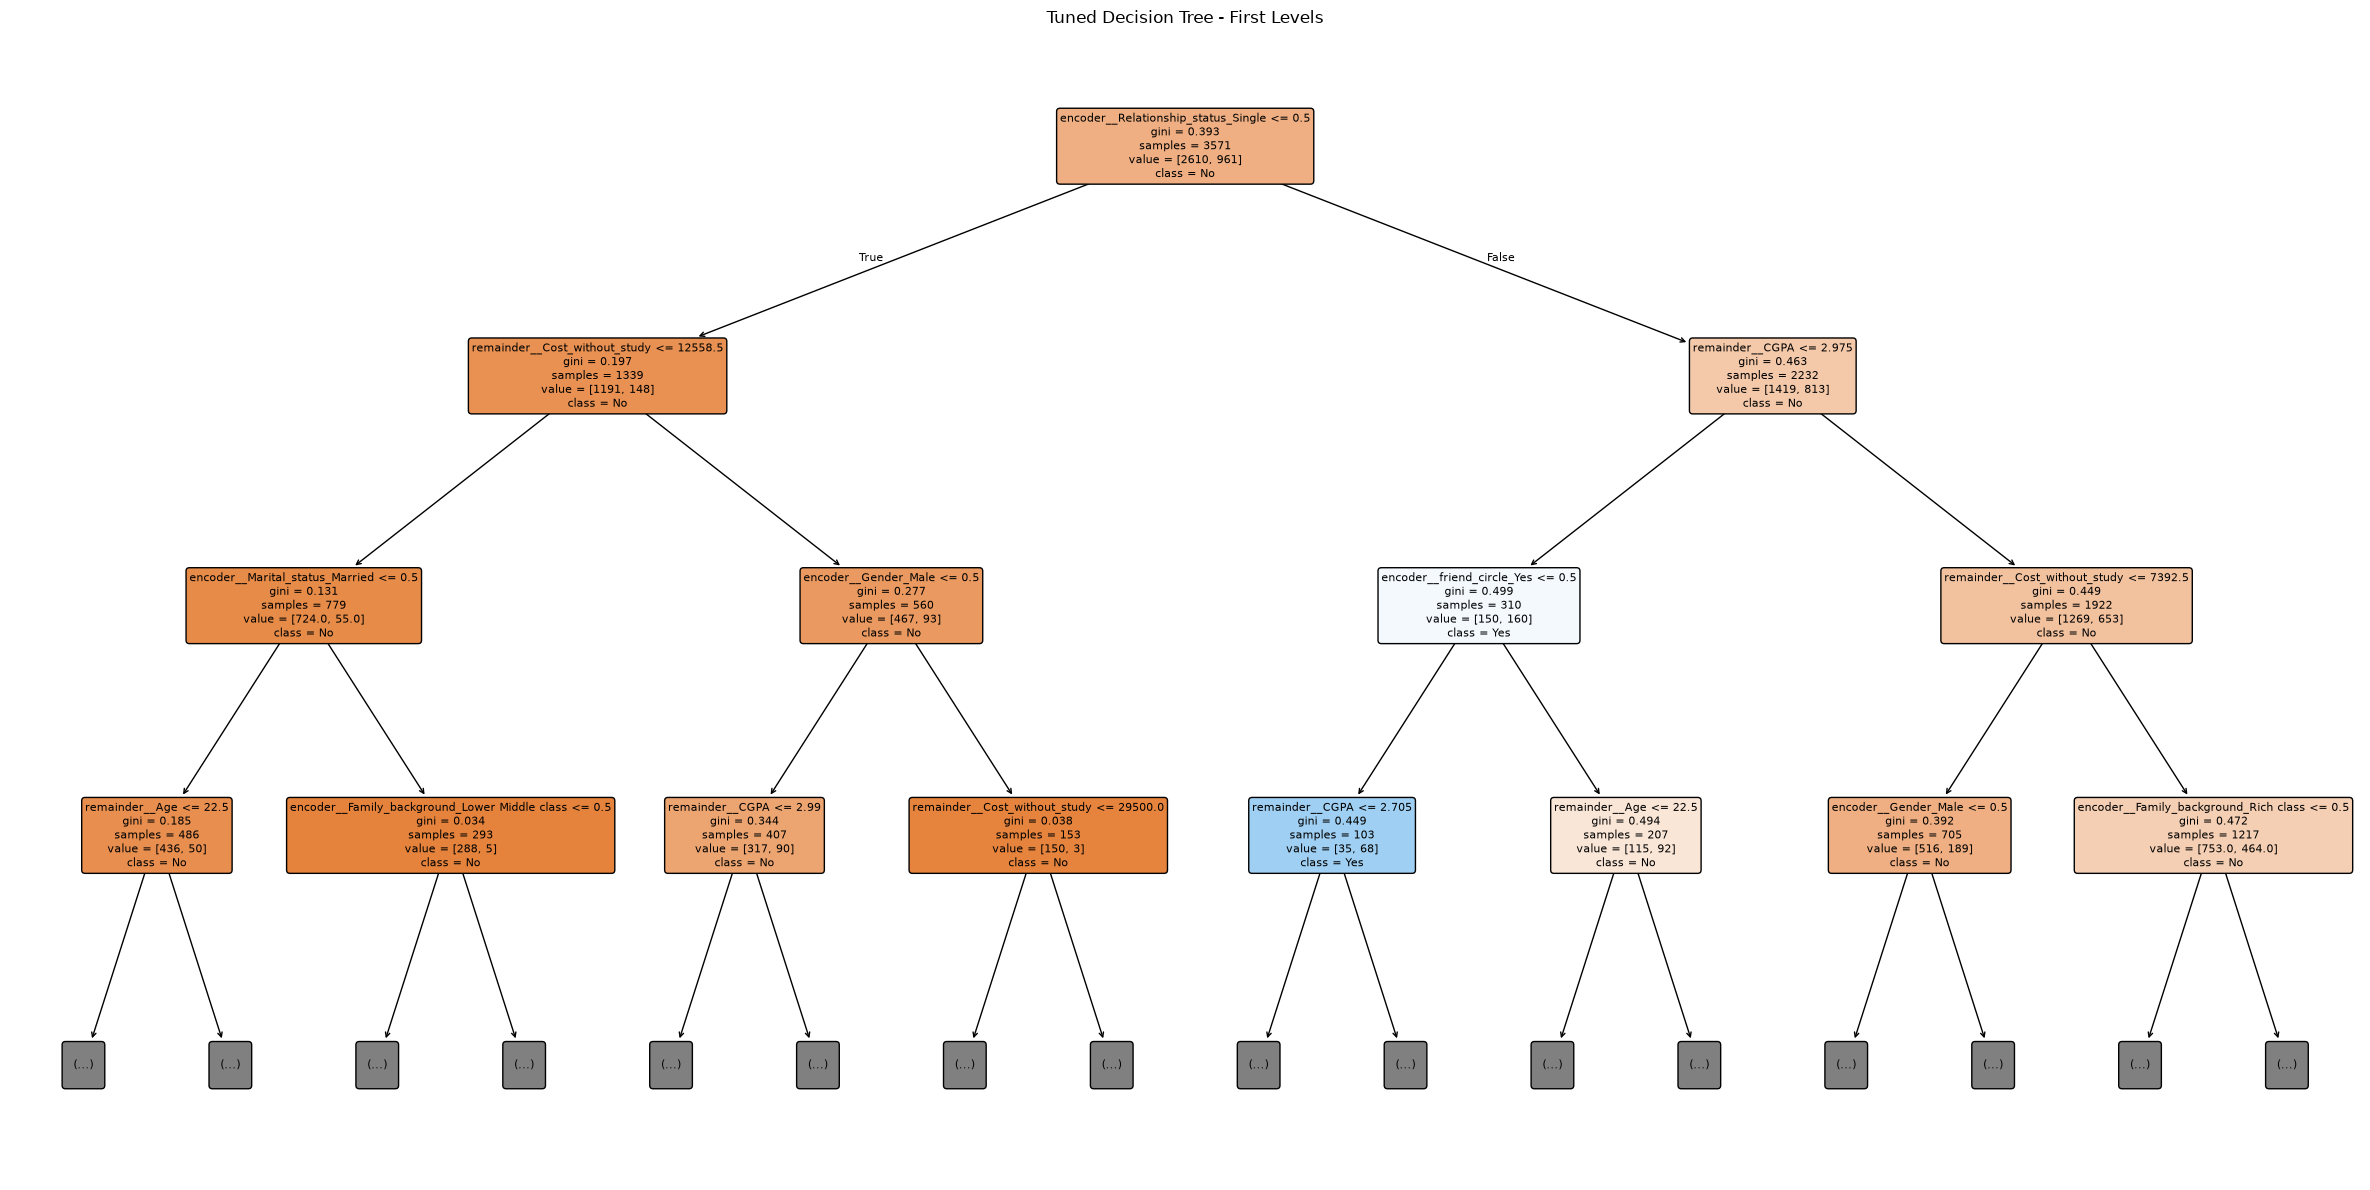

In [29]:
# Decision Tree Visualization Without Health Condition
fitted_preprocessor = best_model_new.named_steps["preprocessor_new"]
best_tree = best_model_new.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    best_tree,
    feature_names=feature_names,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Tuned Decision Tree - First Levels")
plt.tight_layout()
plt.show()

In [30]:
# Decision Tree Using Health Condition Only
X_health = df[["Health_condition"]]
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_health,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
num_cols_h = X_train_h.select_dtypes(include="number").columns
cat_cols_h = X_train_h.select_dtypes(include="str").columns
preprocessor_h = ColumnTransformer(
    transformers=[
        ("encoder", OneHotEncoder(handle_unknown="ignore"), cat_cols_h)
    ],
    remainder="passthrough"
)
tree_pipeline_h = Pipeline([
    ("preprocessor_h", preprocessor_h),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])
tree_pipeline_h.fit(X_train_h, y_train_h)

train_predictions_h = tree_pipeline_h.predict(X_train_h)
test_predictions_h = tree_pipeline_h.predict(X_test_h)

print("\nINITIAL MODEL")
print("Train Accuracy:", accuracy_score(y_train_h, train_predictions_h))
print("Test Accuracy:", accuracy_score(y_test_h, test_predictions_h))

print("\nInitial classification report:")
print(classification_report(
    y_test_h,
    test_predictions_h,
    target_names=["No", "Yes"],
    zero_division=0
))


INITIAL MODEL
Train Accuracy: 0.8913469616353963
Test Accuracy: 0.896976483762598

Initial classification report:
              precision    recall  f1-score   support

          No       0.97      0.88      0.93       653
         Yes       0.75      0.93      0.83       240

    accuracy                           0.90       893
   macro avg       0.86      0.91      0.88       893
weighted avg       0.91      0.90      0.90       893



In [31]:
# Hyperparameter Tuning – Health Condition Only
param_grid = {
    "classifier__max_depth": [3, 5, 8, 12, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10]
}

grid_search_h = GridSearchCV(
    estimator=tree_pipeline_h,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True
)
grid_search_h.fit(X_train_h, y_train_h)

best_model_h = grid_search_h.best_estimator_
print("\nBEST PARAMETERS:")
print(grid_search_h.best_params_)
print("\nBest mean cross-validation F1:", grid_search_h.best_score_)


BEST PARAMETERS:
{'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best mean cross-validation F1: 0.8218106190079638


In [32]:
# Tuned Model – Health Condition Only
train_predictions_h = best_model_h.predict(X_train_h)
test_predictions_h = best_model_h.predict(X_test_h)

In [33]:
print("\nTUNED MODEL")
print("Train Accuracy:", accuracy_score(y_train_h, train_predictions_h))
print("Test Accuracy:", accuracy_score(y_test_h, test_predictions_h))

print("\nTest Precision:", precision_score(
    y_test_h, test_predictions_h, zero_division=0
))
print("Test Recall:", recall_score(
    y_test_h, test_predictions_h, zero_division=0
))
print("Test F1-score:", f1_score(
    y_test_h, test_predictions_h, zero_division=0
))

print("\nFinal classification report:")
print(classification_report(
    y_test_h,
    test_predictions_h,
    target_names=["No", "Yes"],
    zero_division=0
))


TUNED MODEL
Train Accuracy: 0.8913469616353963
Test Accuracy: 0.896976483762598

Test Precision: 0.7466666666666667
Test Recall: 0.9333333333333333
Test F1-score: 0.8296296296296296

Final classification report:
              precision    recall  f1-score   support

          No       0.97      0.88      0.93       653
         Yes       0.75      0.93      0.83       240

    accuracy                           0.90       893
   macro avg       0.86      0.91      0.88       893
weighted avg       0.91      0.90      0.90       893



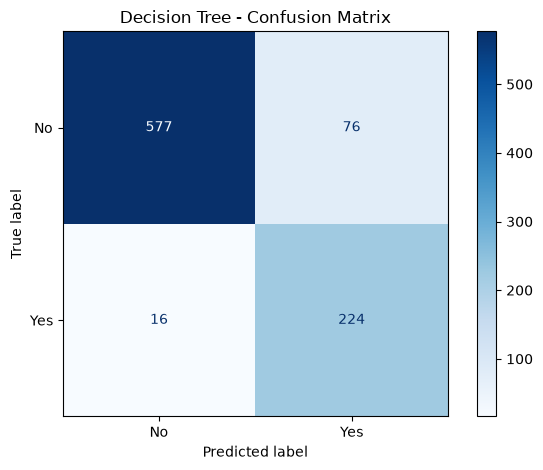

In [34]:
# Confusion Matrix – Health Condition Only
ConfusionMatrixDisplay.from_predictions(
    y_test_h,
    test_predictions_h,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

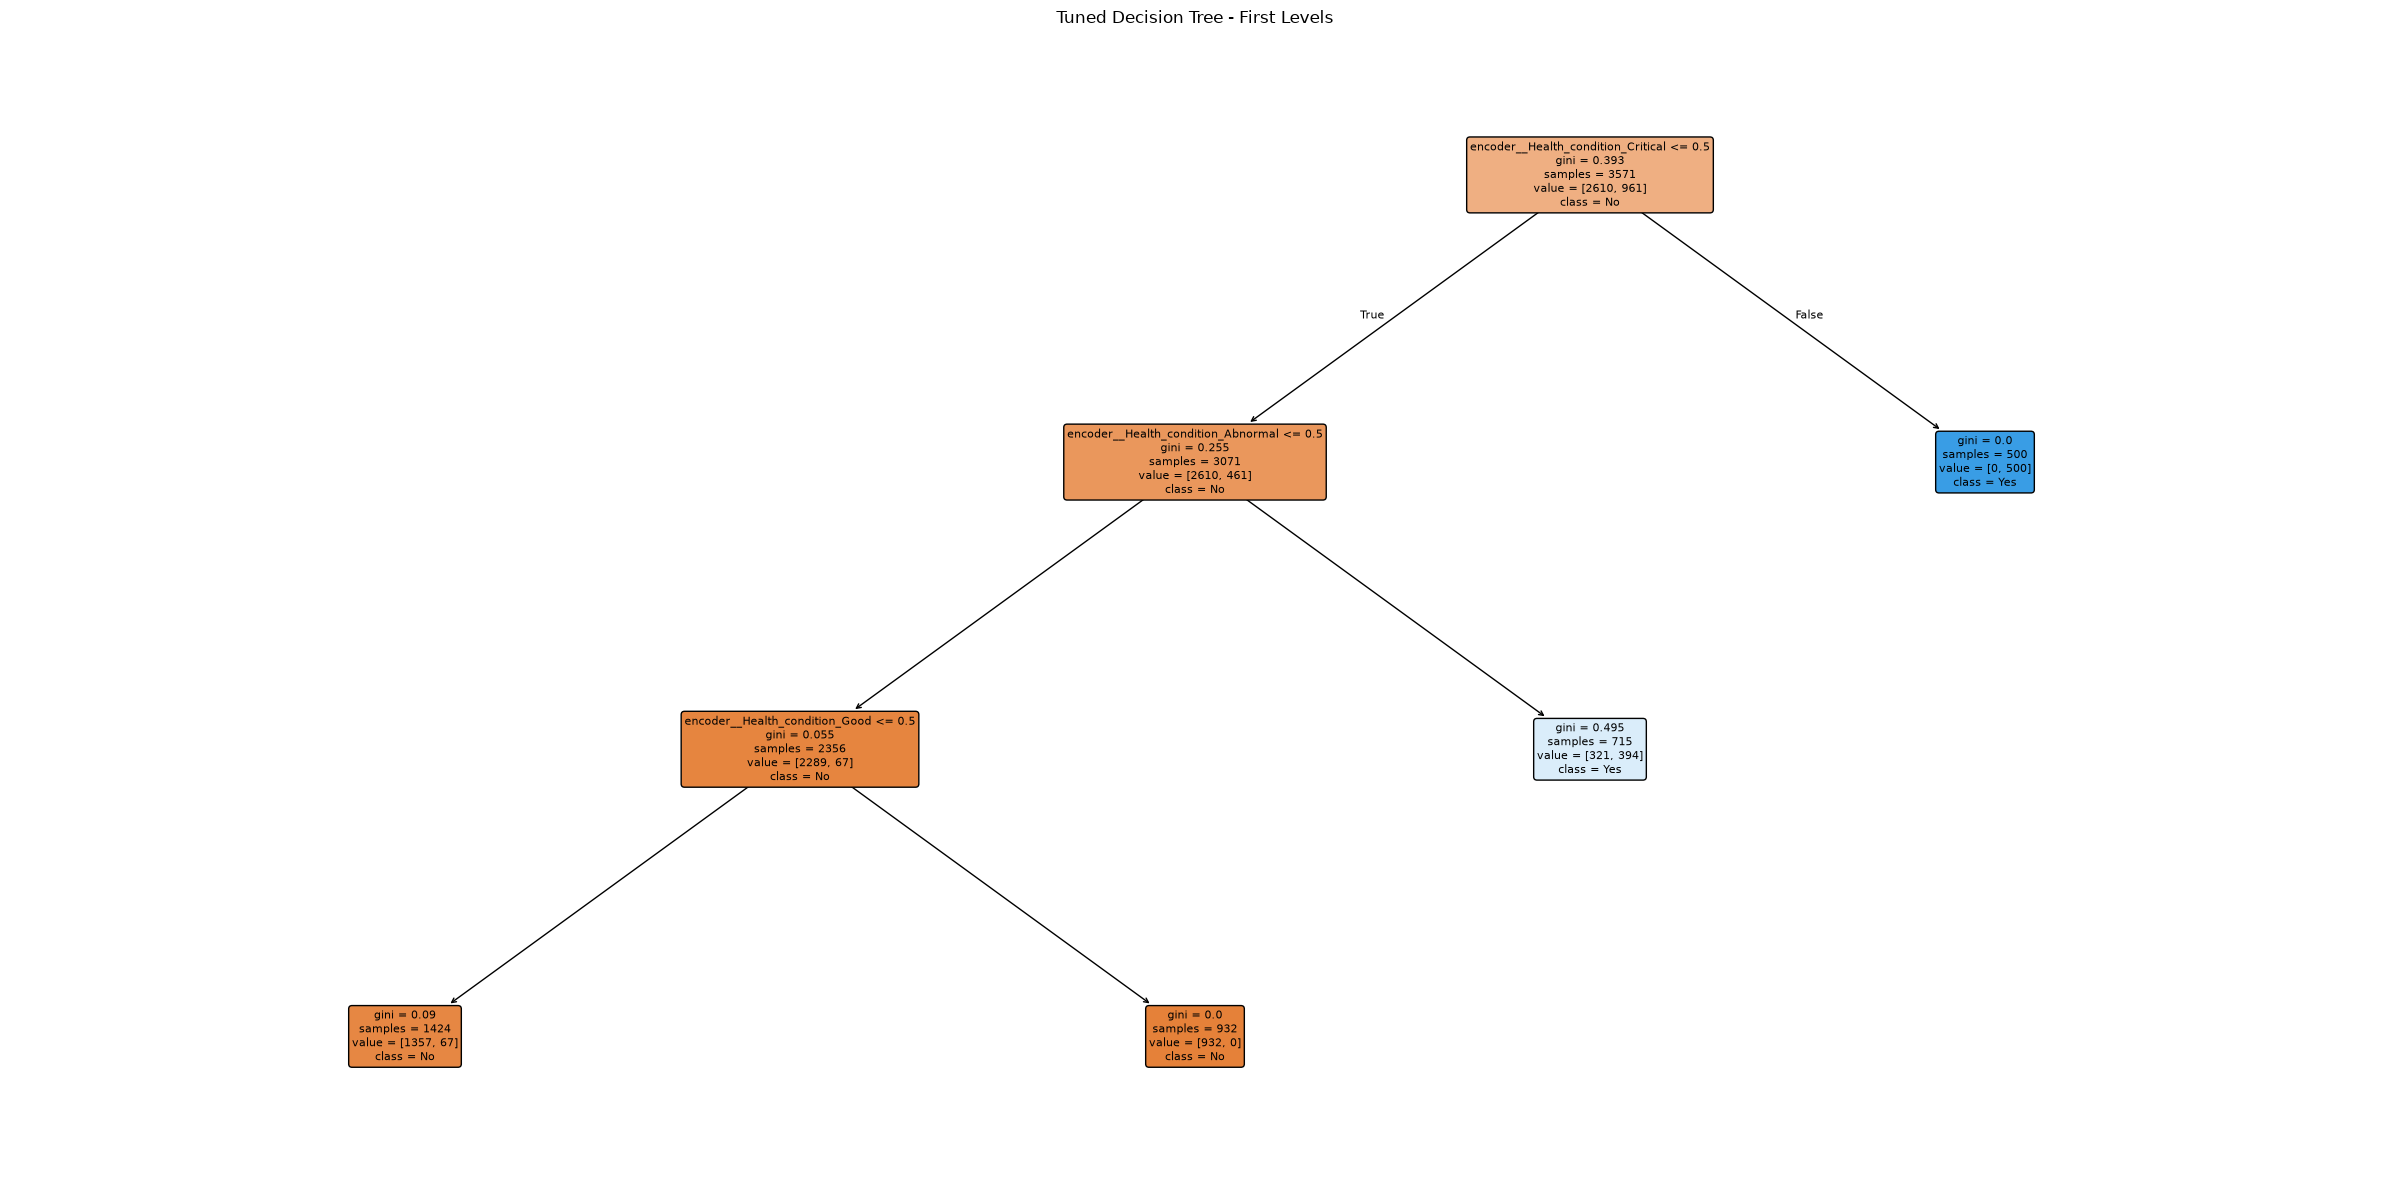

In [35]:
# Decision Tree Visualization – Health Condition Only
fitted_preprocessor = best_model_h.named_steps["preprocessor_h"]
best_tree = best_model_h.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    best_tree,
    feature_names=feature_names,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Tuned Decision Tree - First Levels")
plt.tight_layout()
plt.show()

In [36]:
# Feature Importance Analysis
best_tree = best_model.named_steps["classifier"]

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = pd.Series(
    best_tree.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importances.head(15))

encoder__Health_condition_Critical                0.448646
encoder__Health_condition_Abnormal                0.216412
encoder__Relationship_status_Single               0.158340
encoder__Marital_status_Unmarried                 0.047791
encoder__Family_background_Rich class             0.044142
remainder__CGPA                                   0.023979
encoder__Health_condition_Normal                  0.016888
remainder__Current_semester                       0.014436
encoder__friend_circle_No                         0.014170
encoder__Relationship_status_In a Relationship    0.012903
encoder__Health_condition_Good                    0.001634
encoder__Marital_status_Separated                 0.000380
encoder__Living_style_Family                      0.000279
encoder__Relationship_status_Complicated          0.000000
encoder__Family_background_Middle class           0.000000
dtype: float64


In [37]:
# Health Condition Distribution
print(df["Health_condition"].value_counts())

Health_condition
Normal      1787
Good        1162
Abnormal     881
Critical     634
Name: count, dtype: int64


In [38]:
# Investigating Potential Target Leakage
health_prediction = df["Health_condition"].map({
    "Critical": 1,
    "Good": 0,
    "Abnormal": np.nan,
    "Normal": np.nan
})

known_mask = health_prediction.notna()

print("Number of directly classified rows:",
      known_mask.sum())

print("Percentage of dataset:",
      round(known_mask.mean() * 100, 2), "%")

print("\nAccuracy on directly classified rows:",
      accuracy_score(
          y[known_mask],
          health_prediction[known_mask]
      ))

Number of directly classified rows: 1796
Percentage of dataset: 40.23 %

Accuracy on directly classified rows: 1.0


In [39]:
# Check whether identical feature combinations
# have conflicting target labels

duplicate_groups = (
    df.groupby(list(X.columns), dropna=False)["Depression"]
      .nunique()
)

conflicting_groups = duplicate_groups[duplicate_groups > 1]

print("Conflicting feature groups:", len(conflicting_groups))

Conflicting feature groups: 0


In [42]:
# Cross-Validation: Health Condition vs Dummy Classifier
from sklearn.model_selection import cross_validate, StratifiedKFold
X_health = df[["Health_condition"]]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

health_tree = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

dummy = DummyClassifier(strategy="most_frequent")

tree_scores = cross_validate(
    health_tree,
    X_health,
    y,
    cv=cv,
    scoring=scoring
)

dummy_scores = cross_validate(
    dummy,
    X_health,
    y,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    print(f"\n{metric.upper()}")
    print("Decision Tree:",
          round(tree_scores[f"test_{metric}"].mean(), 3))
    print("Dummy:",
          round(dummy_scores[f"test_{metric}"].mean(), 3))


ACCURACY
Decision Tree: 0.892
Dummy: 0.731

PRECISION
Decision Tree: 0.738
Dummy: 0.0

RECALL
Decision Tree: 0.931
Dummy: 0.0

F1
Decision Tree: 0.823
Dummy: 0.0
